# Student Depression Prediction

# 1. Import Libraries

In [77]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pickle

# 2.  Load Dataset

In [78]:
student_data = pd.read_csv("../data/Student_Depression_Dataset.csv")

student_data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [79]:
student_data.shape

(4464, 13)

# 3. Exploratory Data Analysis

## 3.1 Dataset Summary

In [80]:
student_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [81]:
student_data.duplicated().sum()

np.int64(0)

In [82]:
student_data.columns = student_data.columns.str.lower()

In [83]:
student_data.head()

,gender,age,family_background,relationship_status,marital_status,living_style,current_semester,cgpa,friend_circle,health_condition,cost_without_study,home_division,depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [84]:
numerical_columns = student_data.select_dtypes(include=["int64", "float64"]).columns.tolist()

numerical_columns

['age', 'current_semester', 'cgpa', 'cost_without_study']

In [85]:
categorical_columns = student_data.select_dtypes(include=["str"]).columns.tolist()

categorical_columns

['gender',
 'family_background',
 'relationship_status',
 'marital_status',
 'living_style',
 'friend_circle',
 'health_condition',
 'home_division',
 'depression']

In [86]:
student_data[numerical_columns].describe()

,age,current_semester,cgpa,cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


## 3.2 Target Variable Analysis

In [87]:
student_data["depression"].value_counts()

depression
No     3263
Yes    1201
Name: count, dtype: int64

In [88]:
student_data["depression"].value_counts(normalize=True) * 100

depression
No     73.095878
Yes    26.904122
Name: proportion, dtype: float64

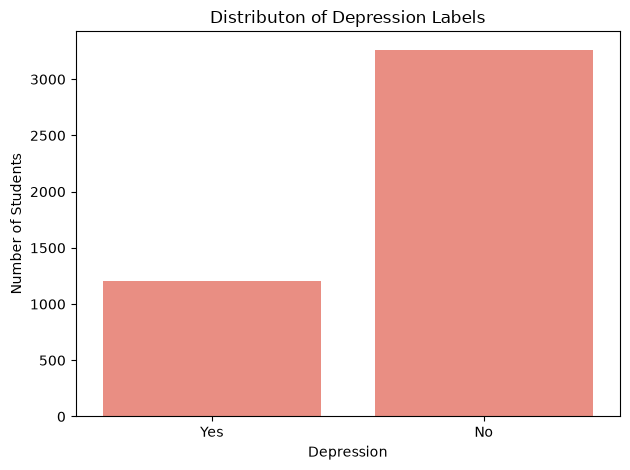

In [89]:
sns.countplot(
    data=student_data,
    x="depression",
    color="salmon"
)

plt.title("Distributon of Depression Labels")
plt.xlabel("Depression")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

Important to note here that the Depression target variable is imbalanced. The No label account for 73.1% of students and the Yes label represents 26.9%.

## 3.3 Numerical Features

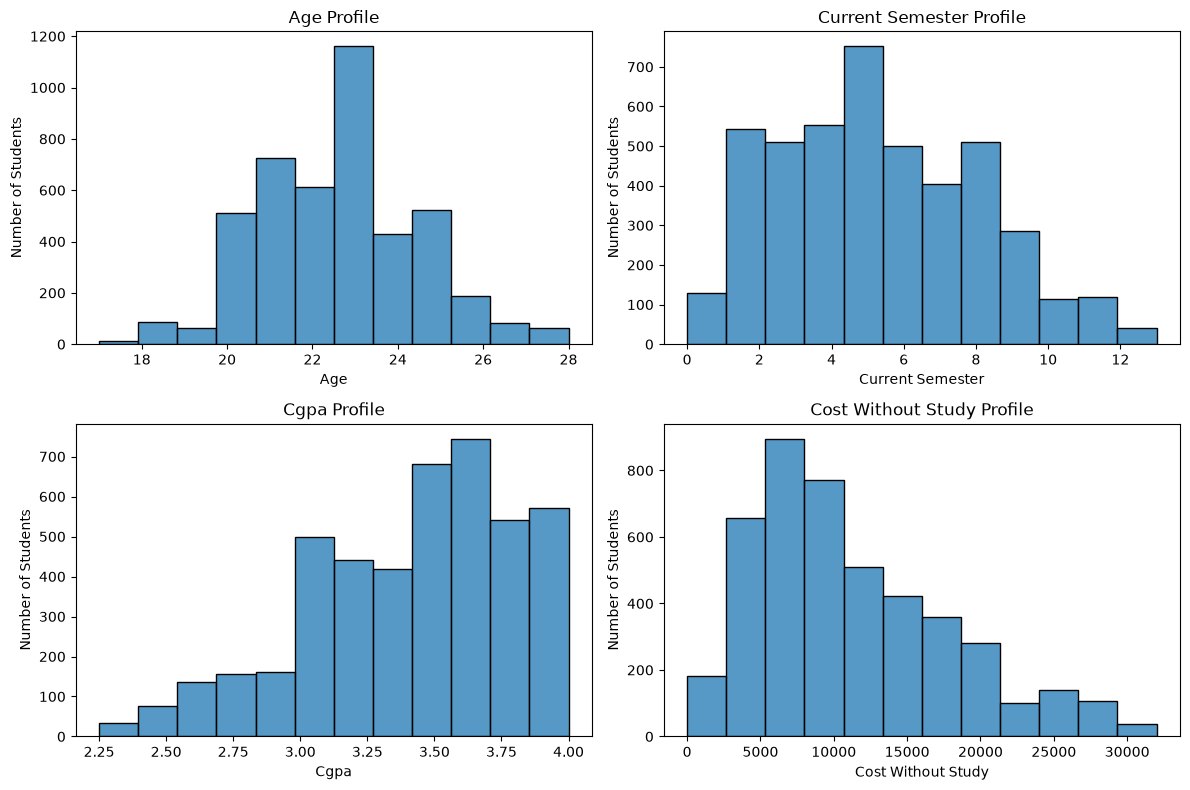

In [90]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, axis in zip(numerical_columns, axes.flatten()):
    sns.histplot(
        data=student_data,
        x=feature,
        bins=12,
        ax=axis
    )

    axis.set_title(f"{feature.replace('_', ' ').title()} Profile")
    axis.set_xlabel(feature.replace("_", " ").title())
    axis.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

The numerical features show different patterns across the dataset.

- **Age:** Most students are in their early twenties. Age 23 appears most frequently.
- **Current Semester:** Semester 5 has the highest frequency at approximately 700 students. Recorded values range from 0 to 13.
- **CGPA:** Values are concentrated toward the higher end of the scale. The highest frequency is around 3.6.
- **Cost Without Study:** Most values fall between 5,000 and 10,000. The distribution is right-skewed and has a mean of approximately 11,243 and a median of 9,500.

## 3.4 Categorical Features

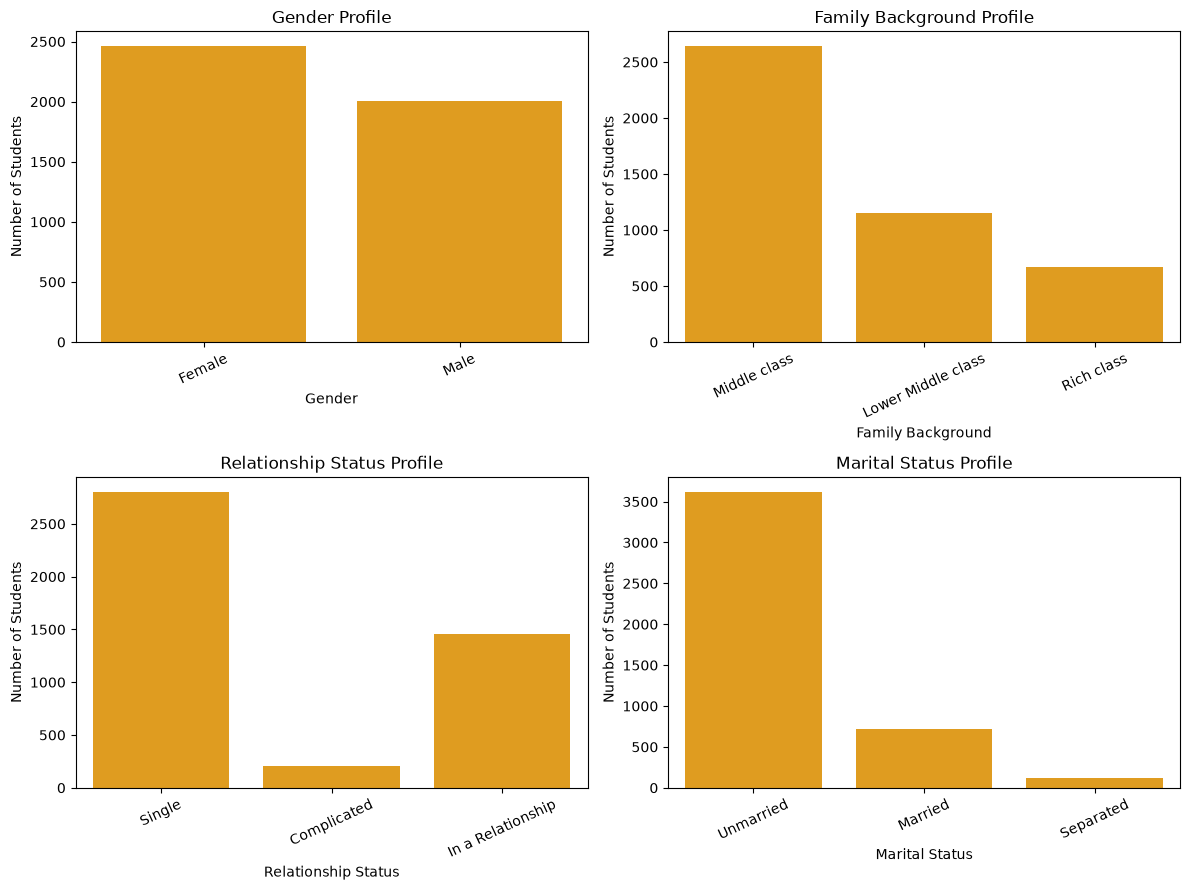

In [91]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

categorical_features_group_1 = [
    "gender",
    "family_background",
    "relationship_status",
    "marital_status"
]

for feature, axis in zip(categorical_features_group_1, axes.flatten()):
    sns.countplot(
        data=student_data,
        x=feature,
        color="orange",
        ax=axis
    )

    axis.set_title(f"{feature.replace('_', ' ').title()} Profile")
    axis.set_xlabel(feature.replace("_", " ").title())
    axis.set_ylabel("Number of Students")
    axis.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

- **Gender:** Female students represent 55.2% of the dataset and male students 44.8%.
- **Family Background:** Most students are classified as Middle class at 59.2%, followed by Lower Middle class 25.8% and Rich class 15.0%.
- **Relationship Status:** Most students are Single at 62.8%, followed by In a Relationship, 32.6% and Complicated at 4.6%.
- **Marital Status:** The majority of students, 81.1%, are Unmarried. Married students are 16.2% and students labeled as Separated are at 2.7%.

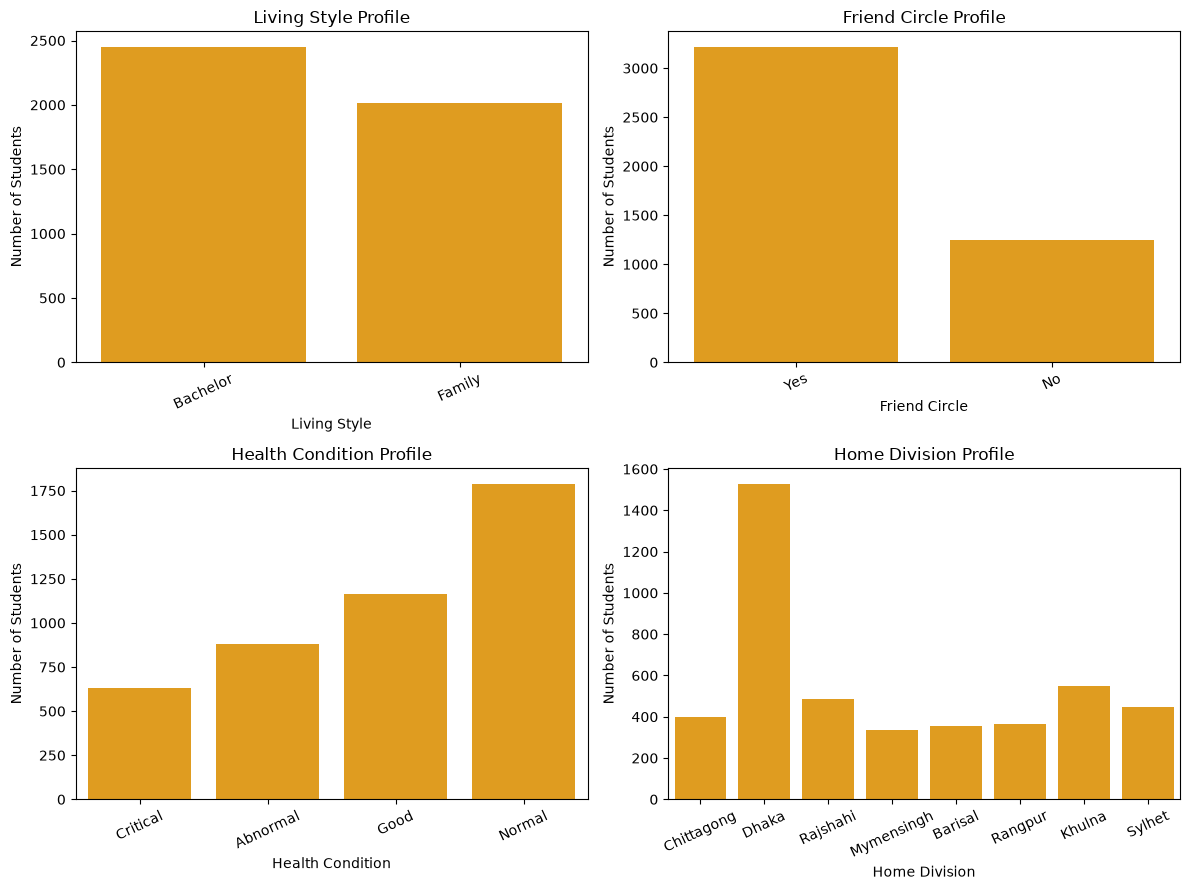

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

categorical_features_group_2 = [
    "living_style",
    "friend_circle",
    "health_condition",
    "home_division"
]

for feature, axis in zip(categorical_features_group_2, axes.flatten()):
    sns.countplot(
        data=student_data,
        x=feature,
        color="orange",
        ax=axis
    )

    axis.set_title(f"{feature.replace('_', ' ').title()} Profile")
    axis.set_xlabel(feature.replace("_", " ").title())
    axis.set_ylabel("Number of Students")
    axis.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

- **Living Style:** 54.9% of students live as Bachelor, while 45.1% live with Family.
- **Friend Circle:** 72.1% of students report having a friend circle. The remaining 27.9% report not having one.
- **Health Condition:** Normal is the most common category at 40.0%. Good represents 26.0%, Abnormal 19.7%, and Critical 14.2%.
- **Home Division:** Dhaka has the highest representation at 34.2%. Khulna follows at 12.3% and Rajshahi, 10.9%.

## 3.5 Feature Relationship with Target

In [93]:
pd.crosstab(
    student_data["health_condition"],
    student_data["depression"],
    normalize="index"
) * 100

depression,No,Yes
health_condition,,
Abnormal,45.062429,54.937571
Critical,0.000000,100.000000
Good,100.000000,0.000000
Normal,95.355344,4.644656


**Health Condition and Depresion**


The depression label percentages differ substantially across health-condition categories. The Critical category has 100% Yes labels, followed by Abnormal at 54.9%. Good has 100% No labels, and Normal has 95.4% No labels.

In [94]:
student_data["health_condition"].value_counts()

health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64

The category counts are substantial, ranging from 634 to 1,787 students.

In [95]:
depression_by_friend_circle = pd.crosstab(
    student_data["friend_circle"],
    student_data["depression"],
    normalize="index"
) * 100

depression_by_friend_circle.round(1)

depression,No,Yes
friend_circle,,
No,65.7,34.3
Yes,76.0,24.0


**Friend Circle and Depression**

Students without a friend circle have a higher proportion of depression labels at 34.3% compared with students who have a friend circle 24%. This represents a difference of 10.3 percentage points between the two groups.

In [96]:
depression_by_marital_status = pd.crosstab(
    student_data["marital_status"],
    student_data["depression"],
    normalize="index"
) * 100

depression_by_marital_status.round(1)

depression,No,Yes
marital_status,,
Married,88.0,12.0
Separated,80.0,20.0
Unmarried,69.9,30.1


**Marital Status and Depression**

Unmarried students have the highest proportion of depression labels at 30.1%, followed by Separated students at 20.0%. Married students have the lowest proportion at 12.0%.

# 4. Setting Up Validation Framework

In [99]:
df_full_train, df_test = train_test_split(
    student_data,
    test_size=0.2,
    random_state=42,
    stratify=student_data["depression"]
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=42,
    stratify=df_full_train["depression"]
)

len(df_train), len(df_val), len(df_test)

(2678, 893, 893)

In [100]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [101]:
y_train = df_train["depression"].map({"No": 0, "Yes": 1}).values
y_val = df_val["depression"].map({"No": 0, "Yes": 1}).values
y_test = df_test["depression"].map({"No": 0, "Yes": 1}).values

del df_train["depression"]
del df_val["depression"]
del df_test["depression"]

In [102]:
print("Training features:", df_train.shape)
print("Training target:", y_train.shape)

print("\nValidation features:", df_val.shape)
print("Validation target:", y_val.shape)

print("\nTest features:", df_test.shape)
print("Test target:", y_test.shape)

Training features: (2678, 12)
Training target: (2678,)

Validation features: (893, 12)
Validation target: (893,)

Test features: (893, 12)
Test target: (893,)


In [103]:
print("Training target distribution:")
print(pd.Series(y_train).value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(pd.Series(y_val).value_counts(normalize=True).round(3))

print("\nTest target distribution:")
print(pd.Series(y_test).value_counts(normalize=True).round(3))

Training target distribution:
0    0.731
1    0.269
Name: proportion, dtype: float64

Validation target distribution:
0    0.731
1    0.269
Name: proportion, dtype: float64

Test target distribution:
0    0.731
1    0.269
Name: proportion, dtype: float64


# 5. Model Training

In [108]:
# Convert training and validation DataFrames into dictionaries
training_records = df_train.to_dict(orient="records")
validation_records = df_val.to_dict(orient="records")

# Initialize DictVectorizer
dict_vectorizer = DictVectorizer(sparse=False)

# Fit vectorizer on training data
X_train = dict_vectorizer.fit_transform(training_records)

# Transform validation data using fitted vectorizer
X_val = dict_vectorizer.transform(validation_records)

print("Training features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)

Training features shape: (2678, 31)
Validation features shape: (893, 31)


## 5.1 Logistic Regression Model

In [109]:
# Initialize Logistic Regression
logistic_regression_model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_regression_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [111]:
# Generate predictions for the validation set
y_val_predicted = logistic_regression_model.predict(X_val)

# Generate probabilities for the positive class (Yes)
y_val_probability = logistic_regression_model.predict_proba(X_val)[:, 1]

print("Predictions:", y_val_predicted[:10])
print("Probabilities:", y_val_probability[:10])

Predictions: [0 0 0 0 0 1 1 0 1 0]
Probabilities: [0.21706187 0.00435326 0.13654586 0.08480271 0.01670218 0.95542474
 0.64593712 0.00187718 0.67959523 0.08592333]


## 5.2 Logistic Regression Evaluation

In [112]:
# Calculate validation metrics
logistic_regression_accuracy = logistic_regression_model.score(X_val, y_val)
logistic_regression_precision = precision_score(y_val, y_val_predicted)
logistic_regression_recall = recall_score(y_val, y_val_predicted)
logistic_regression_f1 = f1_score(y_val, y_val_predicted)
logistic_regression_roc_auc = roc_auc_score(y_val, y_val_probability)

# Display validation metrics
print(f"Accuracy:  {logistic_regression_accuracy:.3f}")
print(f"Precision: {logistic_regression_precision:.3f}")
print(f"Recall:    {logistic_regression_recall:.3f}")
print(f"F1 Score:  {logistic_regression_f1:.3f}")
print(f"ROC AUC:   {logistic_regression_roc_auc:.3f}")

Accuracy:  0.963
Precision: 0.937
Recall:    0.925
F1 Score:  0.931
ROC AUC:   0.990


**Important Observation**

The Logistic Regression model achieved strong results across all five evaluation metrics. It has an accuracy of 96.3% and a ROC AUC of 0.990. These results suggest strong predictive relationships within the dataset.

As pointed out in the EDA section, the unusually strong relationship between health_condition and the target variable needs further investigation. Feature importance analysis and additional checks will help determine whether this item contributes to the high model performance or introduces potential target leakage.

## 5.3 Logistic Regression Hyperparameter Tuning

In [113]:
from sklearn.metrics import accuracy_score

# Parameter values
regularization_values = [0.01, 0.1, 1.0, 10.0]

# Store evaluation results
logistic_regression_tuning_results = []

In [114]:
for regularization_value in regularization_values:

    tuned_logistic_regression_model = LogisticRegression(
        solver="liblinear",
        C=regularization_value,
        max_iter=1000,
        random_state=42
    )

    tuned_logistic_regression_model.fit(X_train, y_train)

    validation_predictions = tuned_logistic_regression_model.predict(X_val)
    validation_probabilities = tuned_logistic_regression_model.predict_proba(X_val)[:, 1]

    logistic_regression_tuning_results.append({
        "C": regularization_value,
        "Accuracy": accuracy_score(y_val, validation_predictions),
        "Precision": precision_score(y_val, validation_predictions),
        "Recall": recall_score(y_val, validation_predictions),
        "F1 Score": f1_score(y_val, validation_predictions),
        "ROC AUC": roc_auc_score(y_val, validation_probabilities)
    })

In [115]:
logistic_regression_tuning_results_df = pd.DataFrame(
    logistic_regression_tuning_results
)

logistic_regression_tuning_results_df

,C,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,0.01,0.902576,0.975155,0.654167,0.783042,0.985630
1,0.10,0.963046,0.940426,0.920833,0.930526,0.989095
2,1.00,0.963046,0.936709,0.925000,0.930818,0.989631
3,10.00,0.963046,0.936709,0.925000,0.930818,0.989695


The Logistic Regression model achieved its strongest overall performance with C values of 1.0 and 10.0. Both configurations produced an F1 score of 0.931 and an accuracy of 96.3%.

The C value of 0.01 resulted in substantially lower recall and F1 scores. Increasing C to 10.0 offered no meaningful improvement over the baseline configuration.

The baseline configuration with C = 1.0 was retained due to its strong performance and slightly stronger regularization.

## 5.4 Decision Tree Model

In [116]:
# Initialize Decision Tree
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [118]:
y_val_predicted_decision_tree = decision_tree_model.predict(X_val)

y_val_probability_decision_tree = decision_tree_model.predict_proba(X_val)[:, 1]

## 5.5 Decision Tree Evaluation

In [119]:
decision_tree_accuracy = accuracy_score(y_val, y_val_predicted_decision_tree)
decision_tree_precision = precision_score(y_val, y_val_predicted_decision_tree)
decision_tree_recall = recall_score(y_val, y_val_predicted_decision_tree)
decision_tree_f1 = f1_score(y_val, y_val_predicted_decision_tree)
decision_tree_roc_auc = roc_auc_score(y_val, y_val_probability_decision_tree)

print(f"Accuracy:  {decision_tree_accuracy:.3f}")
print(f"Precision: {decision_tree_precision:.3f}")
print(f"Recall:    {decision_tree_recall:.3f}")
print(f"F1 Score:  {decision_tree_f1:.3f}")
print(f"ROC AUC:   {decision_tree_roc_auc:.3f}")

Accuracy:  0.987
Precision: 0.967
Recall:    0.983
F1 Score:  0.975
ROC AUC:   0.986


## 5.6 Decision Tree Hyperparameter Tuning

In [120]:
tree_depth_values = [3, 5, 10, None]
minimum_leaf_sizes = [1, 5, 10]

decision_tree_tuning_results = []

In [121]:
for tree_depth in tree_depth_values:
    for minimum_leaf_size in minimum_leaf_sizes:

        tuned_decision_tree_model = DecisionTreeClassifier(
            max_depth=tree_depth,
            min_samples_leaf=minimum_leaf_size,
            random_state=42
        )

        tuned_decision_tree_model.fit(X_train, y_train)

        validation_predictions = tuned_decision_tree_model.predict(X_val)
        validation_probabilities = tuned_decision_tree_model.predict_proba(X_val)[:, 1]

        decision_tree_tuning_results.append({
            "Max Depth": tree_depth,
            "Min Samples Leaf": minimum_leaf_size,
            "Accuracy": accuracy_score(y_val, validation_predictions),
            "Precision": precision_score(y_val, validation_predictions),
            "Recall": recall_score(y_val, validation_predictions),
            "F1 Score": f1_score(y_val, validation_predictions),
            "ROC AUC": roc_auc_score(y_val, validation_probabilities)
        })

In [122]:
decision_tree_tuning_results_df = pd.DataFrame(
    decision_tree_tuning_results
)

decision_tree_tuning_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Max Depth,Min Samples Leaf,Accuracy,Precision,Recall,F1 Score,ROC AUC
6,10.0,1,0.986562,0.967213,0.983333,0.975207,0.986294
9,NaN,1,0.986562,0.967213,0.983333,0.975207,0.985541
8,10.0,10,0.985442,0.991342,0.954167,0.972399,0.990706
11,NaN,10,0.985442,0.991342,0.954167,0.972399,0.990706
7,10.0,5,0.977604,0.950820,0.966667,0.958678,0.993460
10,NaN,5,0.977604,0.950820,0.966667,0.958678,0.993460
3,5.0,1,0.975364,0.995455,0.912500,0.952174,0.993731
4,5.0,5,0.975364,0.995455,0.912500,0.952174,0.993597
5,5.0,10,0.975364,0.995455,0.912500,0.952174,0.993275
0,3.0,1,0.961926,0.929167,0.929167,0.929167,0.982048


The Decision Tree performed best with a maximum depth of 10 and a minimum leaf size of 1. This configuration achieved an F1 score of 0.975 and an accuracy of 98.7%.

The unrestricted tree produced close to identical results and increasing the minimum leaf size reduced recall. Hyperparameter tuning did not meaningfully improve the baseline model.

## 5.7 XGBoost Model

In [123]:
xgboost_model = XGBClassifier(
    eta=0.1,
    max_depth=6,
    min_child_weight=1,
    random_state=42,
    eval_metric="logloss"
)

xgboost_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [124]:
y_val_predicted_xgboost = xgboost_model.predict(X_val)

y_val_probability_xgboost = xgboost_model.predict_proba(X_val)[:, 1]

## 5.8 XGBoost Evaluation

In [125]:
xgboost_accuracy = accuracy_score(y_val, y_val_predicted_xgboost)
xgboost_precision = precision_score(y_val, y_val_predicted_xgboost)
xgboost_recall = recall_score(y_val, y_val_predicted_xgboost)
xgboost_f1 = f1_score(y_val, y_val_predicted_xgboost)
xgboost_roc_auc = roc_auc_score(y_val, y_val_probability_xgboost)

print(f"Accuracy:  {xgboost_accuracy:.3f}")
print(f"Precision: {xgboost_precision:.3f}")
print(f"Recall:    {xgboost_recall:.3f}")
print(f"F1 Score:  {xgboost_f1:.3f}")
print(f"ROC AUC:   {xgboost_roc_auc:.3f}")

Accuracy:  0.993
Precision: 0.996
Recall:    0.979
F1 Score:  0.987
ROC AUC:   0.999


XGBoost outperformed Logistic Regression and Decision Tree across most evaluation metrics. It recorded the highest accuracy at 99.3%, precision 99.6%, F1 score 0.987, and ROC AUC 0.999. Decision Tree had slightly higher recall at 98.3%, compared with XGBoost at 97.9%.

## 5.9 XGBoost Hyperparameter Tuning

In [126]:
xgboost_eta_values = [0.05, 0.1]
xgboost_max_depth_values = [3, 6]
xgboost_min_child_weight_values = [1, 5]

xgboost_tuning_results = []

In [127]:
for eta_value in xgboost_eta_values:
    for max_depth_value in xgboost_max_depth_values:
        for min_child_weight_value in xgboost_min_child_weight_values:

            tuned_xgboost_model = XGBClassifier(
                eta=eta_value,
                max_depth=max_depth_value,
                min_child_weight=min_child_weight_value,
                random_state=42,
                eval_metric="logloss"
            )

            tuned_xgboost_model.fit(X_train, y_train)

            validation_predictions = tuned_xgboost_model.predict(X_val)
            validation_probabilities = tuned_xgboost_model.predict_proba(X_val)[:, 1]

            xgboost_tuning_results.append({
                "Eta": eta_value,
                "Max Depth": max_depth_value,
                "Min Child Weight": min_child_weight_value,
                "Accuracy": accuracy_score(y_val, validation_predictions),
                "Precision": precision_score(y_val, validation_predictions),
                "Recall": recall_score(y_val, validation_predictions),
                "F1 Score": f1_score(y_val, validation_predictions),
                "ROC AUC": roc_auc_score(y_val, validation_probabilities)
            })

In [128]:
xgboost_tuning_results_df = pd.DataFrame(
    xgboost_tuning_results
)

xgboost_tuning_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Eta,Max Depth,Min Child Weight,Accuracy,Precision,Recall,F1 Score,ROC AUC
6,0.10,6,1,0.993281,0.995763,0.979167,0.987395,0.999075
7,0.10,6,5,0.988802,0.983193,0.975000,0.979079,0.998558
2,0.05,6,1,0.988802,0.991453,0.966667,0.978903,0.998679
3,0.05,6,5,0.983203,0.978723,0.958333,0.968421,0.998737
4,0.10,3,1,0.983203,0.978723,0.958333,0.968421,0.995731
5,0.10,3,5,0.983203,0.978723,0.958333,0.968421,0.995795
0,0.05,3,1,0.974244,0.982222,0.920833,0.950538,0.994101
1,0.05,3,5,0.974244,0.982222,0.920833,0.950538,0.994353


The best-performing XGBoost configuration used an eta of 0.10, a maximum depth of 6, and a minimum child weight of 1. It achieved an F1 score of 0.987 and an accuracy of 99.3%.

Overall, the baseline configuration produced the strongest results. Lower eta values and higher minimum child weights resulted in lower F1 scores.

# 6. Model Comparison

In [129]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_regression_accuracy,
        "Precision": logistic_regression_precision,
        "Recall": logistic_regression_recall,
        "F1 Score": logistic_regression_f1,
        "ROC AUC": logistic_regression_roc_auc
    },
    {
        "Model": "Decision Tree",
        "Accuracy": decision_tree_accuracy,
        "Precision": decision_tree_precision,
        "Recall": decision_tree_recall,
        "F1 Score": decision_tree_f1,
        "ROC AUC": decision_tree_roc_auc
    },
    {
        "Model": "XGBoost",
        "Accuracy": xgboost_accuracy,
        "Precision": xgboost_precision,
        "Recall": xgboost_recall,
        "F1 Score": xgboost_f1,
        "ROC AUC": xgboost_roc_auc
    }
])

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.963046,0.936709,0.925000,0.930818,0.989631
1,Decision Tree,0.986562,0.967213,0.983333,0.975207,0.985541
2,XGBoost,0.993281,0.995763,0.979167,0.987395,0.999075


Based on these validation results, XGBoost is the leading candidate for final model selection.

# 7. Feature Importance Analysis

In [130]:
xgboost_feature_importance = pd.DataFrame({
    "Feature": dict_vectorizer.get_feature_names_out(),
    "Importance": xgboost_model.feature_importances_
})

xgboost_feature_importance = xgboost_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

xgboost_feature_importance

,Feature,Importance
12,health_condition=Critical,0.419053
11,health_condition=Abnormal,0.218497
30,relationship_status=Single,0.144921
25,marital_status=Married,0.039253
27,marital_status=Unmarried,0.028922
13,health_condition=Good,0.026884
29,relationship_status=In a Relationship,0.021531
7,friend_circle=No,0.018786
6,family_background=Rich class,0.018135
3,current_semester,0.011188


Health Condition was the most influential feature in the XGBoost model. When combined, Critical and Abnormal categories are approximately 63.8% of total feature importance. Relationship Status of single was the next most important feature at 14.5%.

Below, a comparison model will be trained without this feature to assess its impact on predictive performance.

In [131]:
# Remove health_condition from training and validation data
training_data_without_health_condition = df_train.drop(
    columns=["health_condition"]
)

validation_data_without_health_condition = df_val.drop(
    columns=["health_condition"]
)

# Convert DataFrames into dictionaries
training_records_without_health_condition = (
    training_data_without_health_condition.to_dict(orient="records")
)

validation_records_without_health_condition = (
    validation_data_without_health_condition.to_dict(orient="records")
)

# Initialize a different DictVectorizer
dict_vectorizer_without_health_condition = DictVectorizer(sparse=False)

# Fit and transform training data
X_train_without_health_condition = (
    dict_vectorizer_without_health_condition.fit_transform(
        training_records_without_health_condition
    )
)

# Transform validation data
X_val_without_health_condition = (
    dict_vectorizer_without_health_condition.transform(
        validation_records_without_health_condition
    )
)

In [132]:
X_train_without_health_condition.shape, X_val_without_health_condition.shape

((2678, 27), (893, 27))

In [133]:
xgboost_model_without_health_condition = XGBClassifier(
    eta=0.1,
    max_depth=6,
    min_child_weight=1,
    random_state=42,
    eval_metric="logloss"
)

xgboost_model_without_health_condition.fit(
    X_train_without_health_condition,
    y_train
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [134]:
y_val_predicted_xgboost_without_health_condition = (
    xgboost_model_without_health_condition.predict(
        X_val_without_health_condition
    )
)

y_val_probability_xgboost_without_health_condition = (
    xgboost_model_without_health_condition.predict_proba(
        X_val_without_health_condition
    )[:, 1]
)

In [135]:
xgboost_without_health_condition_accuracy = accuracy_score(
    y_val,
    y_val_predicted_xgboost_without_health_condition
)

xgboost_without_health_condition_precision = precision_score(
    y_val,
    y_val_predicted_xgboost_without_health_condition
)

xgboost_without_health_condition_recall = recall_score(
    y_val,
    y_val_predicted_xgboost_without_health_condition
)

xgboost_without_health_condition_f1 = f1_score(
    y_val,
    y_val_predicted_xgboost_without_health_condition
)

xgboost_without_health_condition_roc_auc = roc_auc_score(
    y_val,
    y_val_probability_xgboost_without_health_condition
)

print(f"Accuracy:  {xgboost_without_health_condition_accuracy:.3f}")
print(f"Precision: {xgboost_without_health_condition_precision:.3f}")
print(f"Recall:    {xgboost_without_health_condition_recall:.3f}")
print(f"F1 Score:  {xgboost_without_health_condition_f1:.3f}")
print(f"ROC AUC:   {xgboost_without_health_condition_roc_auc:.3f}")

Accuracy:  0.774
Precision: 0.627
Recall:    0.392
F1 Score:  0.482
ROC AUC:   0.760


It is clear that removing health_condition caused a huge decline in model performance. The XGBoost model's accuracy decreased to 77.4% and its F1 score dropped to 0.482. Recall also decreased to 39.2%, indicating that the model missed many students labeled as having depression.

As mentioned during EDA, the target imbalance of 26.9% Yes may have impacted in the model above's recall. However, both models used the same stratified data splits. The large drop in performance suggests that the model depends heavily on health_condition.

XGBoost with health_condition was selected as the final model because it achieved stronger validation results. The relationship between health_condition and the target remains unclear because the dataset documentation does not explain how these variables are connected. This is an important limitation to note.

In [136]:
test_records = df_test.to_dict(orient="records")

X_test = dict_vectorizer.transform(test_records)

X_test.shape

(893, 31)

In [137]:
y_test_predicted = xgboost_model.predict(X_test)

y_test_probability = xgboost_model.predict_proba(X_test)[:, 1]

In [138]:
xgboost_test_accuracy = accuracy_score(y_test, y_test_predicted)
xgboost_test_precision = precision_score(y_test, y_test_predicted)
xgboost_test_recall = recall_score(y_test, y_test_predicted)
xgboost_test_f1 = f1_score(y_test, y_test_predicted)
xgboost_test_roc_auc = roc_auc_score(y_test, y_test_probability)

print(f"Accuracy:  {xgboost_test_accuracy:.3f}")
print(f"Precision: {xgboost_test_precision:.3f}")
print(f"Recall:    {xgboost_test_recall:.3f}")
print(f"F1 Score:  {xgboost_test_f1:.3f}")
print(f"ROC AUC:   {xgboost_test_roc_auc:.3f}")

Accuracy:  0.994
Precision: 0.996
Recall:    0.983
F1 Score:  0.990
ROC AUC:   0.999


The final XGBoost model shows strong results on the test set at 99.4% accuracy and an F1 score of 0.990. The test and validation results has consistent performance across both datasets. The model correctly identified 98.3% of students labeled Yes.